In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

(a) Calculate the Pearson correlation matrix and create an annotated heatmap. Rank all four features by their absolute correlation with Marks, identify the strongest positive and negative relationships, and explain what the coefficients indicate


In [2]:
df = pd.DataFrame({
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 8, 4],
    "Attendance": [55, 60, 65, 70, 75, 80, 85, 95, 62, 78, 90, 68],
    "Assignments": [3, 4, 5, 5, 6, 7, 8, 10, 4, 7, 9, 5],
    "Sleep_Hours": [9, 8, 8, 7, 7, 6, 6, 5, 9, 7, 5, 8],
    "Marks": [40, 45, 50, 58, 65, 72, 78, 95, 43, 70, 90, 52]
})

In [4]:
corr =df.corr()
print(corr)

             Study_Hours  Attendance  Assignments  Sleep_Hours     Marks
Study_Hours     1.000000    0.989582     0.976784    -0.968495  0.981485
Attendance      0.989582    1.000000     0.993060    -0.962128  0.993050
Assignments     0.976784    0.993060     1.000000    -0.952470  0.990728
Sleep_Hours    -0.968495   -0.962128    -0.952470     1.000000 -0.973826
Marks           0.981485    0.993050     0.990728    -0.973826  1.000000


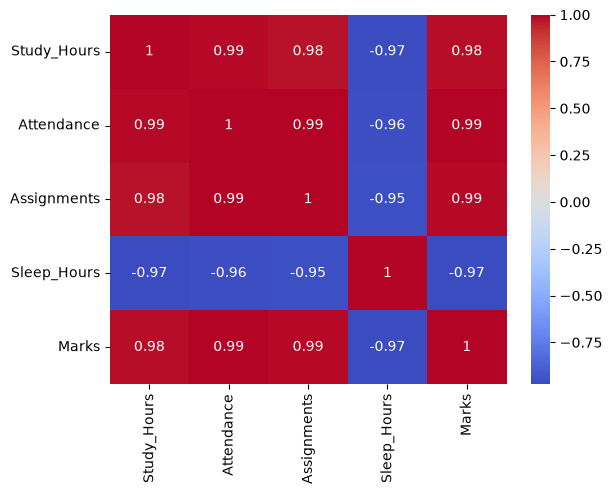

In [5]:
#for heatmap
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.show()

In [6]:
result = corr["Marks"].drop("Marks")
print(result.sort_values(key=abs, ascending=False))

Attendance     0.993050
Assignments    0.990728
Study_Hours    0.981485
Sleep_Hours   -0.973826
Name: Marks, dtype: float64


In [9]:
index=df["Marks"].idxmax()
df_new=df.drop(index)

In [10]:
new_corr=df_new.corr()

In [13]:
print(new_corr["Marks"].drop("Marks"))

Study_Hours    0.977067
Attendance     0.990149
Assignments    0.987145
Sleep_Hours   -0.969244
Name: Marks, dtype: float64


(b) Remove the student with the highest marks and recalculate the correlation matrix. Compare the feature-to-marks correlations before and after removal, and explain how a single observation can influence the results.

In [17]:
index= df["Marks"].idxmax()
print(index)

7


In [18]:
df_new = df.drop(index)

In [20]:
corr_new= df_new.corr()
print(corr)

             Study_Hours  Attendance  Assignments  Sleep_Hours     Marks
Study_Hours     1.000000    0.989582     0.976784    -0.968495  0.981485
Attendance      0.989582    1.000000     0.993060    -0.962128  0.993050
Assignments     0.976784    0.993060     1.000000    -0.952470  0.990728
Sleep_Hours    -0.968495   -0.962128    -0.952470     1.000000 -0.973826
Marks           0.981485    0.993050     0.990728    -0.973826  1.000000


In [21]:
before = df.corr()["Marks"].drop("Marks")
after = corr_new["Marks"].drop("Marks")

comparison = pd.DataFrame({
    "Before": before,
    "After": after
})

print(comparison.round(4))

             Before   After
Study_Hours  0.9815  0.9771
Attendance   0.9930  0.9901
Assignments  0.9907  0.9871
Sleep_Hours -0.9738 -0.9692


(a) Generate a correlation matrix and heatmap. Programmatically identify unique feature pairs whose absolute correlation exceeds 0.90, excluding self-correlations and duplicate pairs. Explain why two highly correlated features may contain redundant information.

In [23]:
df =pd.DataFrame({"Area_sqft": [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
    "Area_sqm": [74.32, 92.90, 111.48, 130.06, 148.64, 167.22, 185.80, 204.38],
    "Bedrooms": [1, 2, 2, 3, 3, 3, 4, 4],
    "Age_Years": [25, 20, 18, 15, 12, 10, 8, 6],
    "Price_Lakhs": [25, 32, 38, 45, 52, 60, 68, 75]})

Correlation Matrix:
             Area_sqft  Area_sqm  Bedrooms  Age_Years  Price_Lakhs
Area_sqft        1.000     1.000     0.958     -0.991        0.999
Area_sqm         1.000     1.000     0.958     -0.991        0.999
Bedrooms         0.958     0.958     1.000     -0.970        0.955
Age_Years       -0.991    -0.991    -0.970      1.000       -0.986
Price_Lakhs      0.999     0.999     0.955     -0.986        1.000


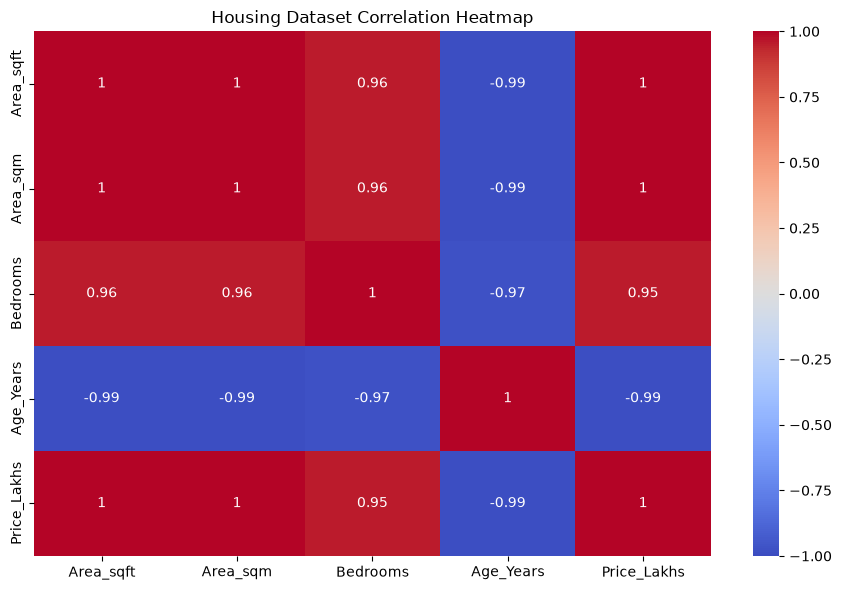


Highly Correlated Feature Pairs:
   Feature 1    Feature 2  Correlation
0  Area_sqft     Area_sqm        1.000
1  Area_sqft     Bedrooms        0.958
2  Area_sqft    Age_Years       -0.991
3  Area_sqft  Price_Lakhs        0.999
4   Area_sqm     Bedrooms        0.958
5   Area_sqm    Age_Years       -0.991
6   Area_sqm  Price_Lakhs        0.999
7   Bedrooms    Age_Years       -0.970
8   Bedrooms  Price_Lakhs        0.955
9  Age_Years  Price_Lakhs       -0.986


In [24]:


# Correlation matrix
corr = df.corr()
print("Correlation Matrix:")
print(corr.round(3))

# Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Housing Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

# Find unique pairs with absolute correlation > 0.90
threshold = 0.90
pairs = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) > threshold:
            pairs.append({
                "Feature 1": corr.columns[i],
                "Feature 2": corr.columns[j],
                "Correlation": value
            })

print("\nHighly Correlated Feature Pairs:")
print(pd.DataFrame(pairs).round(3))


(b) Create two feature sets, one containing both area measurements and another containing only Area_sqft. Compare the feature relationships and explain why correlation can help identify redundancy but cannot, by itself, prove that removing a feature will improve a model.

Set 1: Both Area Features
             Area_sqft  Area_sqm  Bedrooms  Age_Years  Price_Lakhs
Area_sqft        1.000     1.000     0.958     -0.991        0.999
Area_sqm         1.000     1.000     0.958     -0.991        0.999
Bedrooms         0.958     0.958     1.000     -0.970        0.955
Age_Years       -0.991    -0.991    -0.970      1.000       -0.986
Price_Lakhs      0.999     0.999     0.955     -0.986        1.000

Set 2: Only Area_sqft
             Area_sqft  Bedrooms  Age_Years  Price_Lakhs
Area_sqft        1.000     0.958     -0.991        0.999
Bedrooms         0.958     1.000     -0.970        0.955
Age_Years       -0.991    -0.970      1.000       -0.986
Price_Lakhs      0.999     0.955     -0.986        1.000


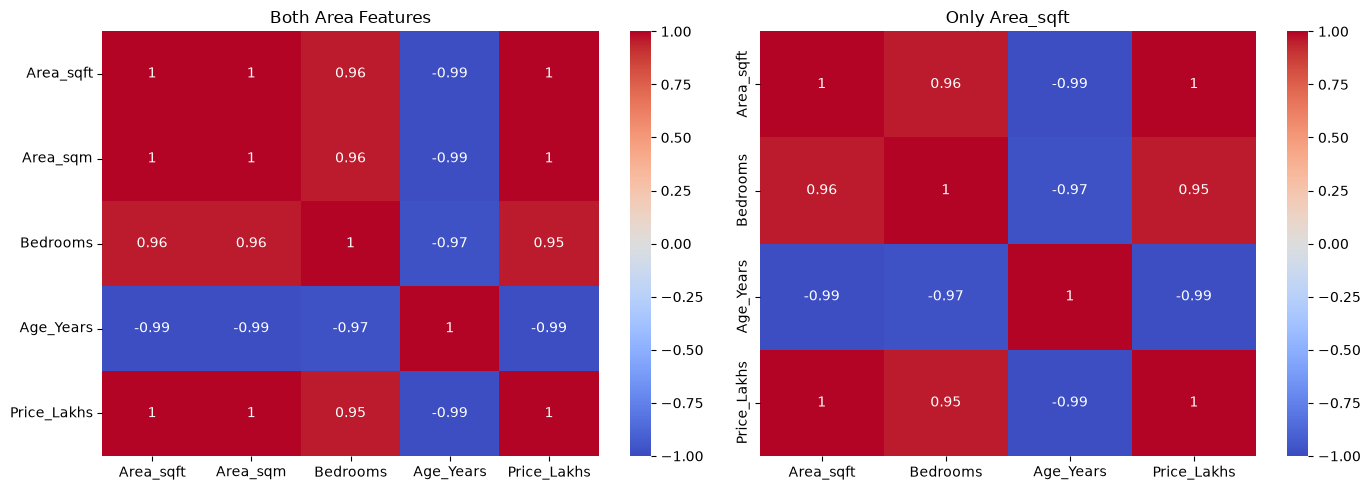

In [25]:

# Feature Set 1: Both area measurements
set1 = df[["Area_sqft", "Area_sqm", "Bedrooms",
           "Age_Years", "Price_Lakhs"]]

# Feature Set 2: Only Area_sqft
set2 = df[["Area_sqft", "Bedrooms",
           "Age_Years", "Price_Lakhs"]]

# Compare correlation matrices
print("Set 1: Both Area Features")
print(set1.corr().round(3))

print("\nSet 2: Only Area_sqft")
print(set2.corr().round(3))

# Plot heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(set1.corr(), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Both Area Features")

sns.heatmap(set2.corr(), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Only Area_sqft")

plt.tight_layout()
plt.show()


(a) Select total_bill, tip, and size. Calculate their Pearson correlation matrix and display an annotated heatmap. Identify the strongest relationship and support your interpretation with the calculated coefficients.

In [27]:

df = sns.load_dataset("tips")

In [29]:
data= df[["total_bill","tip","size"]]

In [30]:
corr_matrix = data.corr(method= "pearson" )
print(corr_matrix)

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


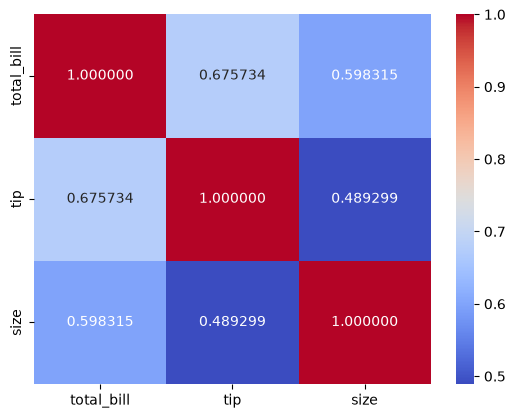

In [31]:
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",fmt='2f')
plt.show()

(b) Create a tip_percentage column using tip / total_bill * 100. Recalculate the correlation matrix and explain how this derived feature relates to total_bill and tip. Discuss why mathematical dependencies between variables can complicate the interpretation of correlation.



In [32]:
df["tip_percentage"]= (df["tip"]/df["total_bill"])*100

In [33]:
data=df[["total_bill","tip","size","tip_percentage"]]
corr_matrix =data.corr()
print(corr_matrix)

                total_bill       tip      size  tip_percentage
total_bill        1.000000  0.675734  0.598315       -0.338624
tip               0.675734  1.000000  0.489299        0.342370
size              0.598315  0.489299  1.000000       -0.142860
tip_percentage   -0.338624  0.342370 -0.142860        1.000000


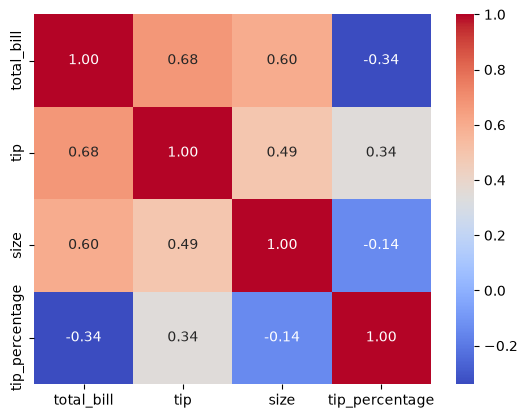

In [35]:
sns.heatmap(corr_matrix,annot=True, cmap="coolwarm",fmt=".2f")
plt.show()

Old correlation: 0.9998682276680948


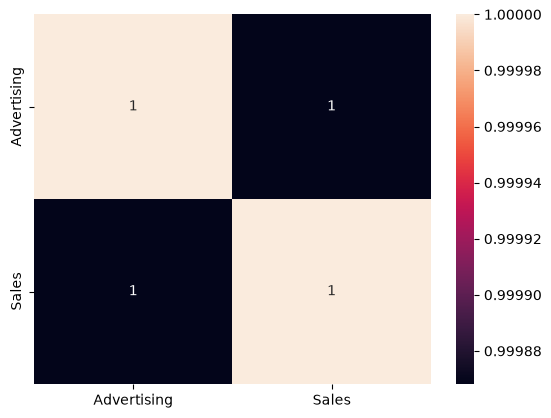

New correlation: 0.06468331541572898


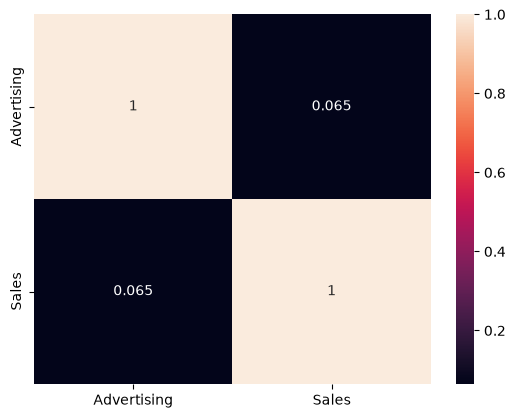

Change: -0.9351849122523658


In [ ]:


df = pd.DataFrame({
    "Advertising": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [20, 28, 35, 42, 50, 58, 65, 72, 80, 88]
})

# Original correlation
r1 = df["Advertising"].corr(df["Sales"])
print("Old correlation:", r1)

sns.heatmap(df.corr(), annot=True)
plt.show()

# Add outlier
df.loc[len(df)] = [100, 10]

# New correlation
r2 = df["Advertising"].corr(df["Sales"])
print("New correlation:", r2)

sns.heatmap(df.corr(), annot=True)
plt.show()

# Correlation change
print("Change:", r2 - r1)


(b) Write Python code to flag potential outliers and compare the correlation before and after adding the unusual observation. Explain why an extreme point can distort the apparent relationship and why it should be investigated before being removed.

In [ ]:
corr_matrix = data.corr(method= "pearson" )
print(corr_matrix)

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


In [58]:
r1 = df["Advertising"].corr(df["Sales"])
print("Before outlier:", r1)

# Add unusual observation
df.loc[len(df)] = [100, 10]

Before outlier: 0.06468331541572898


In [59]:
for col in ["Advertising", "Sales"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col + "_outlier"] = (
        (df[col] < Q1 - 1.5 * IQR) |
        (df[col] > Q3 + 1.5 * IQR)
    )

print(df)


    Advertising  Sales  Advertising_outlier  Sales_outlier
0            10     20                False          False
1            15     28                False          False
2            20     35                False          False
3            25     42                False          False
4            30     50                False          False
5            35     58                False          False
6            40     65                False          False
7            45     72                False          False
8            50     80                False          False
9            55     88                False          False
10          100     10                 True          False
11          100     10                 True          False


In [60]:
# Correlation after adding outlier
r2 = df["Advertising"].corr(df["Sales"])
print("After outlier:", r2)

print("Change in correlation:", r2 - r1)

After outlier: -0.21057103183471357
Change in correlation: -0.27525434725044257
